# DSAA 1001 — Example: loading the data and first checks

**Chicago Food Inspections** (City of Chicago Open Data Portal, dataset 4ijn-s7e5)

This course starter demonstrates basic loading, quality checks, labels and two figures. It is not a complete EDA submission. It has been adapted to the saved historical snapshot and the project directory structure. Re-check every interpretation on the full snapshot; actual coverage is recorded in README.md and download_metadata.json.

To intentionally refresh the snapshot before the project cutoff, run from the repository root: python scripts/download_data.py --overwrite. The preparation script and notebooks work offline.


## 1. Setup

In [1]:
import json
from pathlib import Path

import os
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config/data.json").is_file())
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / "tmp/matplotlib"))

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)

BLUE = "#2a78d6"
ORANGE = "#eb6834"
NEUTRAL = "#898781"
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_MUTED = "#52514e"
GRID = "#e1e0d9"
AXIS = "#c3c2b7"

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": AXIS,
    "axes.labelcolor": INK_MUTED,
    "axes.titlesize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 9,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "text.color": INK,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
})

print("pandas", pd.__version__)

pandas 3.0.6


## 2. Load the data

Load the exact saved gzip CSV from data/raw/. Its associated metadata records the source, download time, row count and actual coverage. The root is located relative to the notebook working directory; no machine-specific path is used.

In [2]:
config = json.loads((ROOT / "config/data.json").read_text(encoding="utf-8"))
DATA_DIR = ROOT / "data/raw"
csv_path = ROOT / config["raw_csv"]
inspections = pd.read_csv(csv_path, dtype="string", keep_default_na=False, na_values=[""])
meta = json.loads((ROOT / config["download_metadata"]).read_text(encoding="utf-8"))
print(f"file            : {csv_path.relative_to(ROOT)}")
print(f"source          : {meta['portal_page']}")
print(f"downloaded (UTC): {meta['downloaded_at_utc']}")
print(f"portal updated  : {meta['portal_rows_updated_at_utc']}")
print(f"shape           : {inspections.shape[0]:,} rows x {inspections.shape[1]} columns")


file            : data\raw\food_inspections.csv.gz
source          : https://data.cityofchicago.org/Health-Human-Services/Food-Inspections/4ijn-s7e5
downloaded (UTC): 2026-10-12T07:59:09+00:00
portal updated  : 2026-10-11T09:06:02+00:00
shape           : 197,882 rows x 17 columns


## 3. What is actually in the file?

In [3]:
inspections.head(3)

,Inspection ID,DBA Name,AKA Name,License #,Facility Type,Risk,Address,City,State,Zip,Inspection Date,Inspection Type,Results,Violations,Latitude,Longitude,Location
0,263804,NEW CHINA BUFFET,NEW CHINA BUFFET,1123902,<NA>,Risk 3 (Low),7566 N WESTERN AVE,CHICAGO,IL,60645,06/30/2017,Canvass,Out of Business,<NA>,42.01918786841174,-87.69032526458456,"(42.01918786841174, -87.69032526458456)"
1,270806,"BLUE SEA, INC.","BLUE SEA, INC.",1518306,<NA>,Risk 3 (Low),4153 W MADISON ST,CHICAGO,IL,60624,02/05/2016,Canvass,Out of Business,<NA>,41.88056136447874,-87.73022041217723,"(41.88056136447874, -87.73022041217723)"
2,455308,MCDONALD'S#20518,MCDONALD'S#20518,1334318,<NA>,Risk 3 (Low),29 N WACKER DR,CHICAGO,IL,60606,11/08/2019,Canvass,Out of Business,<NA>,41.883091005891075,-87.63664592832622,"(41.883091005891075, -87.63664592832622)"


In [4]:
inspections.info()

<class 'pandas.DataFrame'>
RangeIndex: 197882 entries, 0 to 197881
Data columns (total 17 columns):
 #   Column           Non-Null Count   Dtype 
---  ------           --------------   ----- 
 0   Inspection ID    197882 non-null  string
 1   DBA Name         197882 non-null  string
 2   AKA Name         197382 non-null  string
 3   License #        197875 non-null  string
 4   Facility Type    196852 non-null  string
 5   Risk             197843 non-null  string
 6   Address          197882 non-null  string
 7   City             197757 non-null  string
 8   State            197809 non-null  string
 9   Zip              197870 non-null  string
 10  Inspection Date  197882 non-null  string
 11  Inspection Type  197881 non-null  string
 12  Results          197882 non-null  string
 13  Violations       141473 non-null  string
 14  Latitude         197193 non-null  string
 15  Longitude        197193 non-null  string
 16  Location         197193 non-null  string
dtypes: string(17)
memory 

The raw CSV is loaded as strings to preserve IDs and ZIP codes. Inspection Date must be parsed explicitly as MM/DD/YYYY; Latitude and Longitude can be converted to numeric values when needed. IDs are labels, not quantities. The preparation pipeline handles these conversions separately.

In [5]:
inspections["Inspection Date"] = pd.to_datetime(
    inspections["Inspection Date"], format="%m/%d/%Y"
)

print("date range:", inspections["Inspection Date"].min().date(),
      "to", inspections["Inspection Date"].max().date())
print()
print("inspections per day")
print(inspections["Inspection Date"].dt.date.value_counts().sort_index().to_string())

date range: 2016-01-04 to 2026-10-09

inspections per day
Inspection Date
2016-01-04      3
2016-01-05    102
2016-01-06     83
2016-01-07     93
2016-01-08     90
2016-01-11     60
2016-01-12     91
2016-01-13     70
2016-01-14    110
2016-01-15     95
2016-01-19     76
2016-01-20     43
2016-01-21    122
2016-01-22     93
2016-01-25     96
2016-01-26     80
2016-01-27     60
2016-01-28     91
2016-01-29     93
2016-02-02     15
2016-02-03     81
2016-02-04     94
2016-02-05     99
2016-02-08     91
2016-02-09     75
2016-02-10     59
2016-02-11     88
2016-02-16     85
2016-02-17     68
2016-02-18    122
2016-02-19    110
2016-02-22    103
2016-02-23     98
2016-02-24     58
2016-02-25     87
2016-02-26    104
2016-02-29      2
2016-03-01    125
2016-03-02    110
2016-03-03    113
2016-03-04    107
2016-03-08     84
2016-03-09     84
2016-03-10    110
2016-03-11    111
2016-03-14     96
2016-03-15     96
2016-03-16     54
2016-03-17    105
2016-03-18    113
2016-03-20      1
2016-03-

Recent inspection dates may be incomplete because of reporting delays. Check the actual downloaded date range and counts rather than assuming complete coverage through the requested cutoff.

## 4. Missing values

In [6]:
missing = pd.DataFrame({
    "n_missing": inspections.isna().sum(),
    "pct_missing": (100 * inspections.isna().mean()).round(1),
}).sort_values("pct_missing", ascending=False)

missing

,n_missing,pct_missing
Violations,56409,28.5
Facility Type,1030,0.5
Longitude,689,0.3
Location,689,0.3
AKA Name,500,0.3
Latitude,689,0.3
City,125,0.1
Inspection ID,0,0.0
DBA Name,0,0.0
State,73,0.0


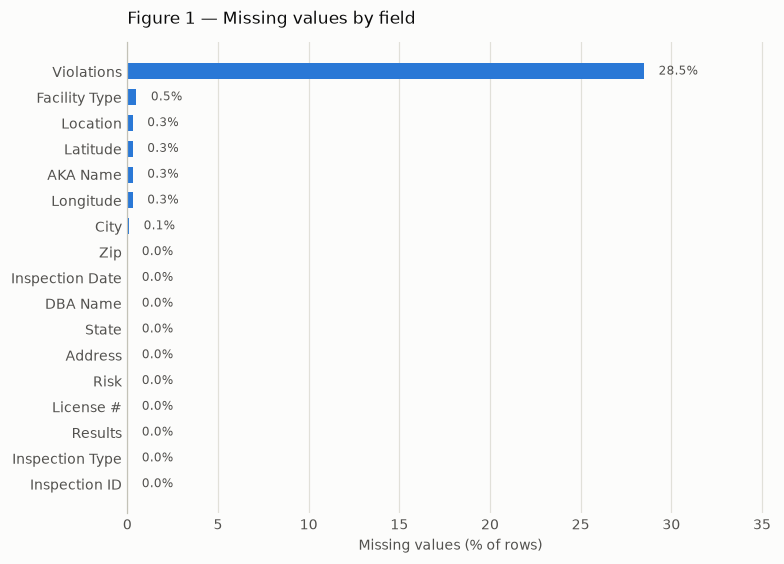

In [7]:
plot_df = missing.sort_values("pct_missing")  # ascending, so barh puts the worst on top
worst_col = missing.index[0]

fig, ax = plt.subplots(figsize=(7.2, 5.2))
ax.barh(plot_df.index, plot_df["pct_missing"], color=BLUE, height=0.62)

for name, pct in plot_df["pct_missing"].items():
    ax.text(pct + 0.8, name, f"{pct:.1f}%", va="center", ha="left",
            fontsize=8, color=INK_MUTED)

ax.set_xlim(0, max(plot_df["pct_missing"].max() * 1.25, 5))
ax.set_xlabel("Missing values (% of rows)")
ax.set_title(f"Figure 1 — Missing values by field",
             loc="left", color=INK, pad=12)
ax.xaxis.grid(True)
ax.set_axisbelow(True)
ax.spines["bottom"].set_visible(False)
ax.tick_params(axis="x", length=0)
ax.tick_params(axis="y", length=0)
fig.tight_layout()
plt.show()

**Figure 1.** Missing rates for the current saved snapshot. Use the plotted values as evidence; the original three-day sample does not describe the full history. Missing Violations can depend on the inspection outcome, and current Violations must never be used to predict that same inspection. Do not infer missing State or City without evidence.

## 5. Duplicates and what one row means

A row is one **inspection**, not one establishment. Two rows sharing a `License #` is legitimate (re-inspections, different types). Don't confuse repeat visits with duplicates.

In [8]:
n = len(inspections)
print(f"rows                              : {n}")
print(f"duplicated `Inspection ID`        : {inspections['Inspection ID'].duplicated().sum()}")
print(f"fully duplicated rows             : {inspections.duplicated().sum()}")
print(f"distinct establishments (License#): {inspections['License #'].nunique()}")
print()

repeat = inspections["License #"].value_counts()
repeat = repeat[repeat > 1]
print(f"establishments inspected more than once in this window: {len(repeat)}")
if len(repeat):
    cols = ["Inspection ID", "DBA Name", "Inspection Date", "Inspection Type", "Results"]
    display(inspections[inspections["License #"].isin(repeat.index)]
            .sort_values(["License #", "Inspection Date"])[cols].head(20))

rows                              : 197882
duplicated `Inspection ID`        : 0


fully duplicated rows             : 0
distinct establishments (License#): 32759

establishments inspected more than once in this window: 25655


,Inspection ID,DBA Name,Inspection Date,Inspection Type,Results
1973,1631643,KOREAN AIR LOUNGE,2016-02-11,Complaint,Fail
2261,1631931,KINGS AND QUEENS,2016-02-19,Canvass,Fail
2293,1631963,PAPA ROMEO'S PIZZA,2016-02-19,Canvass,Out of Business
2652,1632323,TAQUERIA LA CAPITAL,2016-02-26,Canvass,Out of Business
2664,1632335,KINGS AND QUEENS,2016-02-26,Canvass Re-Inspection,No Entry
3526,1633202,NUTRICION FAMILIAR,2016-03-15,Canvass,Out of Business
5685,1750217,BAR RISTA CAFE,2016-04-01,Canvass,Out of Business
6075,1751599,HAT TRICK CATERING,2016-04-07,Complaint,Fail
6456,1751981,HAT TRICK CATERING,2016-04-14,Complaint Re-Inspection,Pass
6485,1752010,CRAFTS SERVICE,2016-04-14,Complaint,Fail


Repeated establishments need an explicit evaluation interpretation. A chronological split may validly measure future inspections of known establishments, unseen establishments, or a mixture. Report that overlap; optional grouped evaluation can assess transfer to unseen establishments. TimeSeriesSplit does not separate establishment groups automatically. Same-day records have no reliable within-day order.

## 6. Categorical fields

How many distinct values per text column, and are they spelled consistently?

In [9]:
for col in ["Facility Type", "Risk", "Inspection Type", "Results"]:
    counts = inspections[col].value_counts(dropna=False)
    print(f"=== {col} — {inspections[col].nunique(dropna=False)} distinct values ===")
    print(counts.head(20).to_string())
    print()

=== Facility Type — 369 distinct values ===
Facility Type
Restaurant                         138442
Grocery Store                       21080
School                              12270
Children's Services Facility         6283
Daycare Above and Under 2 Years      2824
Bakery                               2821
Long Term Care                       1803
Daycare (2 - 6 Years)                1514
Catering                             1274
Mobile Food Preparer                 1132
<NA>                                 1030
Liquor                                809
Hospital                              708
Golden Diner                          570
Shared Kitchen User (Long Term)       345
Shared Kitchen                        300
Mobile Food Dispenser                 298
TAVERN                                258
Special Event                         247
Daycare Combo 1586                    173

=== Risk — 5 distinct values ===
Risk
Risk 1 (High)      154544
Risk 2 (Medium)     31717
Risk 3 (Low

Review category cardinality and spelling on this snapshot. Facility Type is free text; Risk may include categories beyond the three standard levels. Inspection Type is known before the visit and may distinguish first visits from follow-ups. Use counts and evidence before merging categories.

## 7. Building the target

The brief maps `Results` to two labels plus an excluded group:

| `Results` | Label |
|---|---|
| `Fail` | **1** |
| `Pass`, `Pass w/ Conditions` | **0** |
| `Out of Business`, `No Entry`, `Not Ready`, `Business Not Located` | excluded |

Excluded rows are not failures — the inspector never got to inspect. You can still use them for an establishment's **history** if the record predates the inspection being predicted.

In [10]:
LABEL_MAP = {
    "Fail": 1,
    "Pass": 0,
    "Pass w/ Conditions": 0,
}

inspections["label"] = inspections["Results"].map(LABEL_MAP)

labelled = inspections.dropna(subset=["label"]).copy()
labelled["label"] = labelled["label"].astype(int)

print(f"labelled rows: {len(labelled)} of {len(inspections)}")
print(f"excluded rows: {len(inspections) - len(labelled)}")
print()
print("class balance among labelled rows")
print((labelled["label"].value_counts(normalize=True)
       .rename({0: "0 (pass)", 1: "1 (fail)"})
       .mul(100).round(1).astype(str) + " %").to_string())

labelled rows: 167538 of 197882
excluded rows: 30344

class balance among labelled rows
label
0 (pass)    77.4 %
1 (fail)    22.6 %


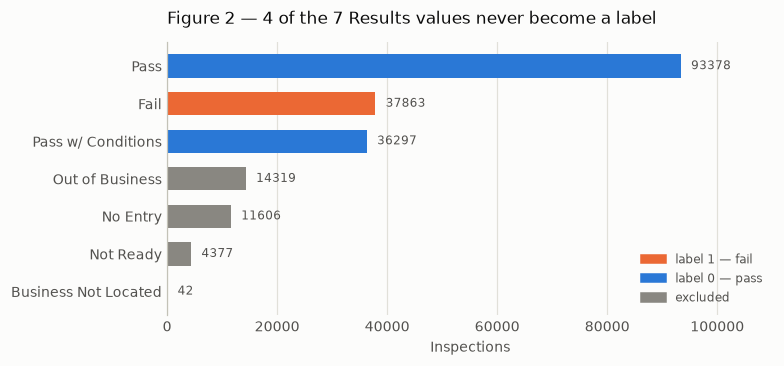

In [11]:
result_counts = inspections["Results"].value_counts().sort_values()
n_excluded_values = sum(r not in LABEL_MAP for r in result_counts.index)


def bar_colour(result: str) -> str:
    if LABEL_MAP.get(result) == 1:
        return ORANGE
    if LABEL_MAP.get(result) == 0:
        return BLUE
    return NEUTRAL


fig, ax = plt.subplots(figsize=(7.2, 3.4))
ax.barh(result_counts.index, result_counts.values,
        color=[bar_colour(r) for r in result_counts.index], height=0.62)

for name, value in result_counts.items():
    ax.text(value + result_counts.max() * 0.02, name, f"{value}",
            va="center", ha="left", fontsize=8, color=INK_MUTED)

handles = [
    plt.Rectangle((0, 0), 1, 1, color=ORANGE),
    plt.Rectangle((0, 0), 1, 1, color=BLUE),
    plt.Rectangle((0, 0), 1, 1, color=NEUTRAL),
]
ax.legend(handles, ["label 1 — fail", "label 0 — pass", "excluded"],
          loc="lower right", frameon=False, fontsize=8, labelcolor=INK_MUTED)

ax.set_xlim(0, result_counts.max() * 1.18)
ax.set_xlabel("Inspections")
ax.set_title(
    f"Figure 2 — {n_excluded_values} of the {len(result_counts)} Results values "
    "never become a label",
    loc="left", color=INK, pad=12,
)
ax.xaxis.grid(True)
ax.set_axisbelow(True)
ax.spines["bottom"].set_visible(False)
ax.tick_params(axis="x", length=0)
ax.tick_params(axis="y", length=0)
fig.tight_layout()
plt.show()

**Figure 2.** Every `Results` value, coloured by label. Grey bars have no pass/fail outcome and leave the labelled set — **row count ≠ training-set size**.

The classes are **imbalanced**, which is why the metric is Macro-F1: a model predicting "pass" for everything scores 0 on the failure class. Check the balance again on the full data.

## 8. Where to take this next

**Use the saved historical snapshot.** To refresh before the cutoff, run `python scripts/download_data.py --overwrite` from the repository root.

**Questions worth a figure:**

1. **Counts over time** — inspections per month since 2016. Where are the discontinuities? Does the failure *rate* move with volume?
2. **Free-text cleanup** — how many real `Facility Type` categories after folding case and spelling? How much do the top 10 cover?
3. **Failure rate by group** — by `Facility Type`, `Inspection Type`, `Risk`, ZIP. Add confidence intervals or counts for small groups.
4. **Inspection history** — inspections per `License #`. Does a past failure predict the next one? Strongest features likely live here.
5. **Leakage audit** — column by column: *would I know this before the inspection?* `Violations` and `Results` fail. History features must use strictly earlier dates.
6. **Geography** — do coordinates add anything beyond ZIP? Check completeness on the full data.

Then write the **data-quality table** and **one-page modelling plan** the brief asks for.